# 🍕 PIZZA SALES REVENUE PREDICTION ANALYTICS USING PYTHON

### A Complete Data Analytics & Machine Learning Project

**Dataset:** `pizza_sales.csv`  
**Records:** 48,620  
**Original variables:** 12  
**Machine Learning Task:** Regression  
**Target Variable:** `total_price`  
**Model:** Linear Regression

---

## 📌 Project Overview

This project studies historical pizza sales data to understand **what sells, when it sells, and how much revenue is generated**.

The project is divided into two connected parts:

1. **Descriptive & Exploratory Analytics** – understand sales patterns through tables and easy-to-read visualizations.
2. **Predictive Analytics** – build a Linear Regression model to estimate `total_price`.

The notebook is designed so that each graph answers a simple business question. Important values are displayed directly on charts wherever practical, making the results easier to explain during a college presentation or viva.


## <font color="Blue"> PROBLEM STATEMENT</FONT>


Pizza businesses generate large amounts of sales data containing information about orders, quantities, prices, pizza categories, sizes, dates, and times. Analyzing this information can help identify sales patterns, understand customer demand, and improve revenue planning.

With the availability of historical pizza sales records, there is an opportunity to use data analytics and machine learning to study revenue behavior. By analyzing order quantity, unit price, pizza size, category, date, and time information, it becomes possible to identify patterns and build a model that estimates the total value of an order.

Therefore, the problem is to analyze the given pizza sales dataset and develop a predictive model that estimates total order revenue using historical sales information. This can help businesses understand sales performance and support better data-driven decisions.


## <font color="Blue"> OBJECTIVE </FONT>


The primary objective of this project is to analyze pizza sales data and build a predictive model to estimate total order revenue using machine learning techniques. The specific objectives are as follows:

- To perform data cleaning and preprocessing by checking missing values, duplicates, and preparing the dataset for analysis
- To conduct Exploratory Data Analysis (EDA) in order to uncover sales patterns, trends, and relationships
- To create useful date-based and time-based features for analysis
- To analyze pizza categories, sizes, quantities, and revenue
- To identify top-performing pizzas based on sales and revenue
- To build a regression model using Linear Regression to predict total order revenue
- To evaluate the model using MAE, MSE, RMSE, and R² score
- To compare actual and predicted revenue
- To interpret the model results and identify useful business insights


## <font color="Blue"> IMAPACT ON BUSINESS </FONT>


This project helps pizza businesses understand their sales performance and revenue patterns. By analyzing historical orders and predicting total order value, the business can better understand demand, identify high-performing products, plan promotions, and support data-driven sales decisions.


## <font color="Blue"> PROBLEM TYPE: </FONT><font color="BROWN"> REGRESSION</font>


## <font color="Blue"> LABEL: </FONT><font color="BROWN"> total_price</font>


<br>


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [3]:
# Plotting helper: keeps charts clean, readable, and presentation-friendly.
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlepad'] = 12
plt.rcParams['axes.labelpad'] = 8
plt.rcParams['font.size'] = 10


## <font color="Blue"> DATA LOADING </FONT>


In [4]:
import pandas as pd
df = pd.read_csv('/content/pizza_sales.csv')

In [5]:
df.head()


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1.0,1.0,hawaiian_m,1.0,1/1/2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2.0,2.0,classic_dlx_m,1.0,1/1/2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3.0,2.0,five_cheese_l,1.0,1/1/2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4.0,2.0,ital_supr_l,1.0,1/1/2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5.0,2.0,mexicana_m,1.0,1/1/2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


### DATASET INFORMATION


In [6]:
df.shape


(48620, 12)

Dataset contain:

- Row = 48620
- Column = 12


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  float64
 1   order_id           48620 non-null  float64
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  float64
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(5), object(7)
memory usage: 4.5+ MB


From the above dataset information, the dataset contains numerical, categorical, date, and time information.

**Quantitative data:** quantity, unit_price, total_price

**Categorical data:** pizza_size, pizza_category, pizza_name_id, pizza_name

**Temporal data:** order_date, order_time


## 🧹 DATA PREPROCESSING

Data preprocessing is the stage where raw sales information is checked and prepared for analysis.

### Main tasks in this project

1. **Missing-value check** – identifies incomplete records.
2. **Duplicate check** – identifies repeated records.
3. **Date conversion** – converts `order_date` into a proper datetime format.
4. **Time conversion** – converts `order_time` so the order hour can be extracted.
5. **Feature engineering** – creates Year, Month, Day, Day Name, Day of Week, Order Hour, and Order Period.
6. **Machine-learning preparation** – converts categorical values into numerical variables and ensures that the model receives clean numeric data.

> **Why this matters:** A machine-learning model cannot reliably work with raw text categories or missing numerical values. Cleaning the data first makes the model more stable and the results easier to interpret.


### MISSING VALUE


In [8]:
df.isnull().sum()


,0
pizza_id,0
order_id,0
pizza_name_id,0
quantity,0
order_date,0
order_time,0
unit_price,0
total_price,0
pizza_size,0
pizza_category,0


The above output is used to identify whether any column contains missing values.


### CHECK DUPLICATE


In [9]:
df.duplicated().sum()


np.int64(0)

The above output is used to identify duplicated records.


### DATA TYPES


### DATE & TIME CONVERSION

The original `pizza_sales.csv` contains dates such as `1/1/2015` and times such as `11:38:36`.

Before creating Year, Month, Day, and Order Period features, the date and time columns must be converted to Pandas datetime values.

**Important:** This cell is deliberately placed before all charts that use `Year`, `Month`, `Day_Name`, or `order_period`. This prevents the `KeyError: 'Year'` problem.

The conversion uses `format='mixed'` so the notebook is more tolerant of different date/time string representations, while invalid values are converted safely to missing values and handled below.


In [10]:
# Convert date and time columns before creating any time-based analysis

df['order_date'] = pd.to_datetime(
    df['order_date'].astype(str).str.strip(),
    format='mixed',
    errors='coerce'
)

df['order_time'] = pd.to_datetime(
    df['order_time'].astype(str).str.strip(),
    format='mixed',
    errors='coerce'
)

# Create date-based features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['Month_Name'] = df['order_date'].dt.month_name()
df['Day'] = df['order_date'].dt.day
df['Day_Name'] = df['order_date'].dt.day_name()
df['Day_of_Week'] = df['order_date'].dt.dayofweek

# Create time-based features
df['order_hour'] = df['order_time'].dt.hour

df['order_period'] = pd.cut(
    df['order_hour'],
    bins=[-1, 6, 11, 15, 18, 21, 24],
    labels=[
        'Late Night',
        'Morning',
        'Lunch',
        'Afternoon',
        'Evening',
        'Night'
    ]
)

# Make sure numeric columns are actually numeric
for col in ['quantity', 'unit_price', 'total_price']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Date dtype :", df['order_date'].dtype)
print("Time dtype :", df['order_time'].dtype)
print("Missing order dates:", df['order_date'].isna().sum())
print("Missing order times:", df['order_time'].isna().sum())

print("\nCreated features:")
print([
    'Year', 'Month', 'Month_Name', 'Day',
    'Day_Name', 'Day_of_Week',
    'order_hour', 'order_period'
])

df.head()


Date dtype : datetime64[ns]
Time dtype : datetime64[ns]
Missing order dates: 0
Missing order times: 0

Created features:
['Year', 'Month', 'Month_Name', 'Day', 'Day_Name', 'Day_of_Week', 'order_hour', 'order_period']


,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name,Year,Month,Month_Name,Day,Day_Name,Day_of_Week,order_hour,order_period
0,1.0,1.0,hawaiian_m,1.0,2015-01-01,2026-09-22 11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,2015,1,January,1,Thursday,3,11,Morning
1,2.0,2.0,classic_dlx_m,1.0,2015-01-01,2026-09-22 11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza,2015,1,January,1,Thursday,3,11,Morning
2,3.0,2.0,five_cheese_l,1.0,2015-01-01,2026-09-22 11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza,2015,1,January,1,Thursday,3,11,Morning
3,4.0,2.0,ital_supr_l,1.0,2015-01-01,2026-09-22 11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza,2015,1,January,1,Thursday,3,11,Morning
4,5.0,2.0,mexicana_m,1.0,2015-01-01,2026-09-22 11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza,2015,1,January,1,Thursday,3,11,Morning


# Revenue by Pizza Category

### What are we trying to understand?
This chart compares the total revenue generated by each pizza category.

### How to read it
- A taller bar means **higher total revenue**.
- The value printed above each bar is the actual revenue.
- This helps identify categories that contribute most to overall sales.


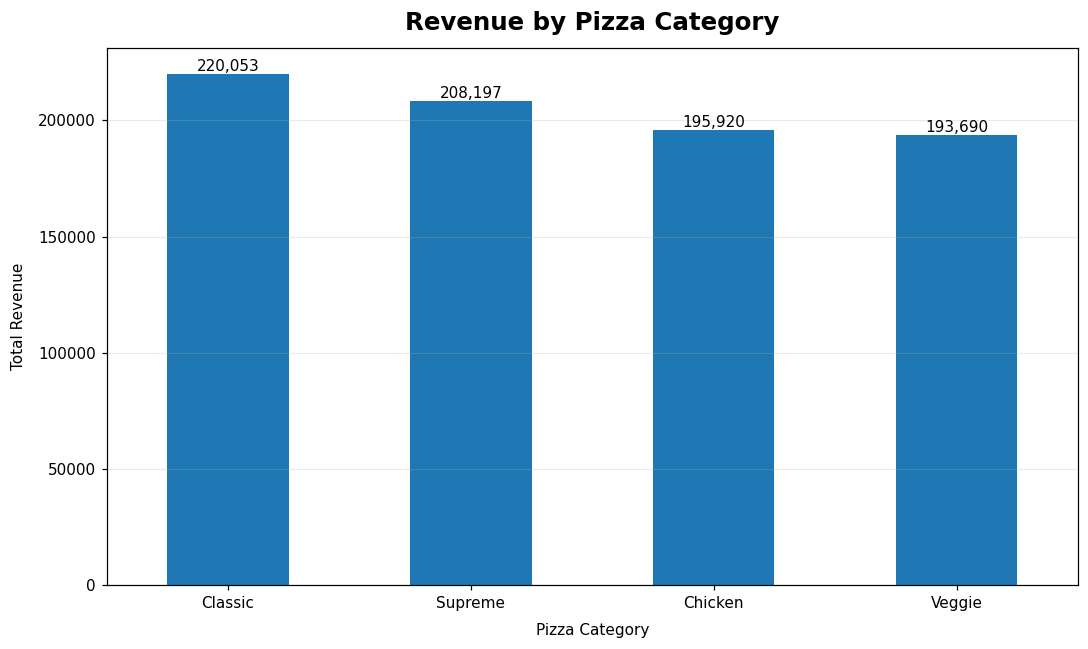

Highest revenue category: Classic
Highest category revenue: 220,053.10


In [11]:
category_revenue = df.groupby('pizza_category')['total_price'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
ax = category_revenue.plot(kind='bar')

plt.title('Revenue by Pizza Category', fontsize=16, fontweight='bold')
plt.xlabel('Pizza Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(category_revenue):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print('Highest revenue category:', category_revenue.idxmax())
print(f'Highest category revenue: {category_revenue.max():,.2f}')


# Quantity Sold by Pizza Category

### What are we trying to understand?
Revenue and quantity are not the same thing. This chart shows **how many pizzas were sold** in each category.

### Why is this useful?
A category can sell many pizzas but generate less revenue if its average selling price is lower.


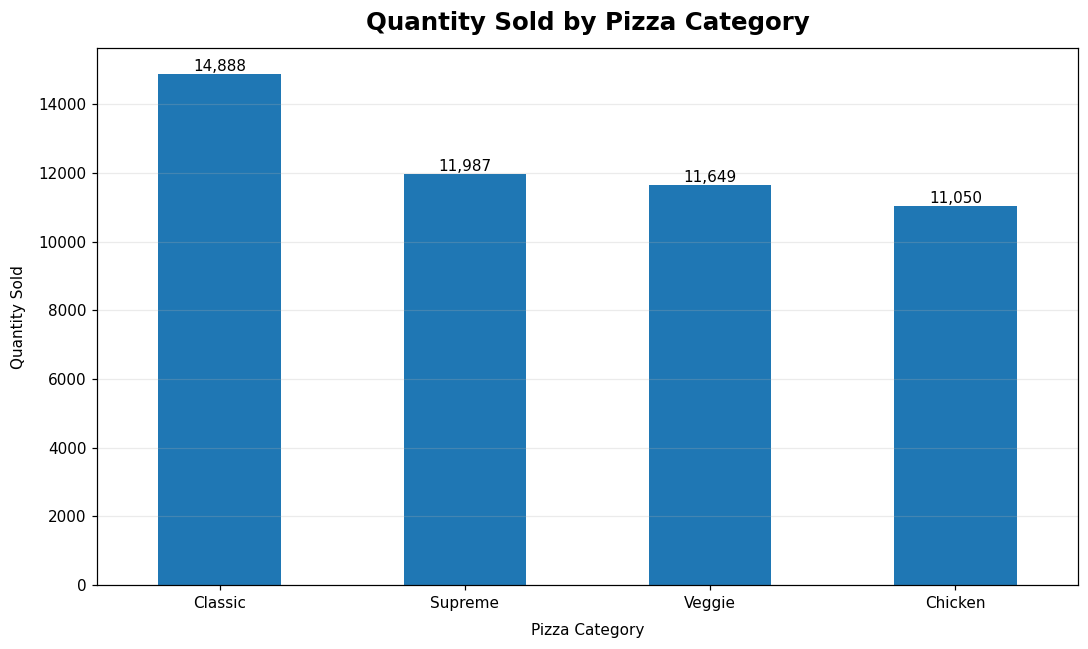

Highest quantity category: Classic
Highest quantity sold: 14,888


In [12]:
category_quantity = df.groupby('pizza_category')['quantity'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
ax = category_quantity.plot(kind='bar')

plt.title('Quantity Sold by Pizza Category', fontsize=16, fontweight='bold')
plt.xlabel('Pizza Category')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(category_quantity):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print('Highest quantity category:', category_quantity.idxmax())
print(f'Highest quantity sold: {category_quantity.max():,.0f}')


# Revenue by Pizza Size

### What are we trying to understand?
This chart compares revenue generated by different pizza sizes.

### Business interpretation
The result helps identify which size contributes most to revenue and can support pricing, promotions, and inventory decisions.


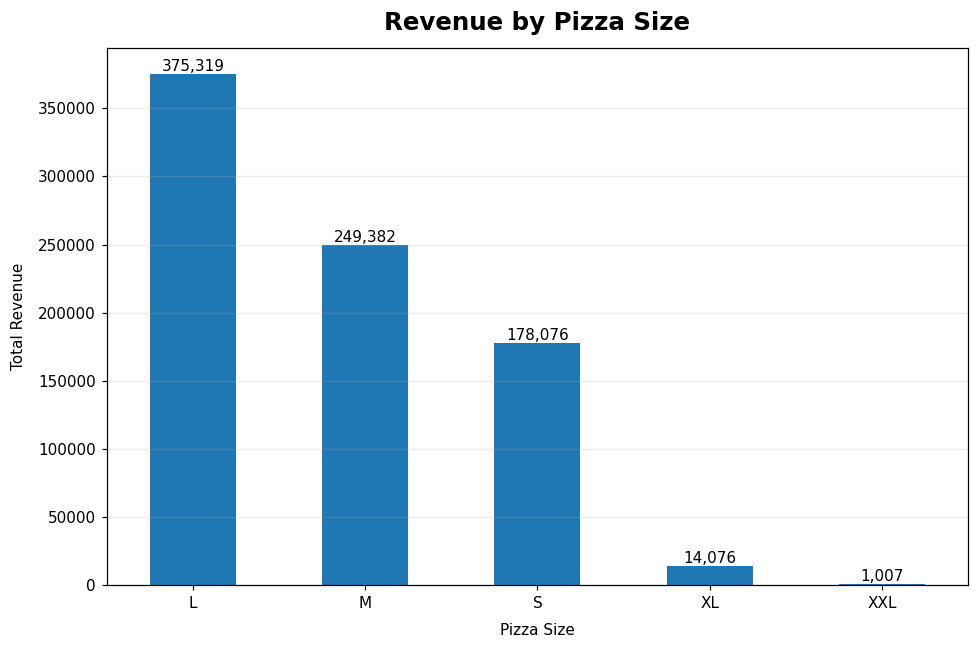

Highest revenue size: L


In [13]:
size_revenue = df.groupby('pizza_size')['total_price'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 6))
ax = size_revenue.plot(kind='bar')

plt.title('Revenue by Pizza Size', fontsize=16, fontweight='bold')
plt.xlabel('Pizza Size')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(size_revenue):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print('Highest revenue size:', size_revenue.idxmax())


# Quantity Sold by Pizza Size

This chart focuses on **customer preference by size** rather than revenue.


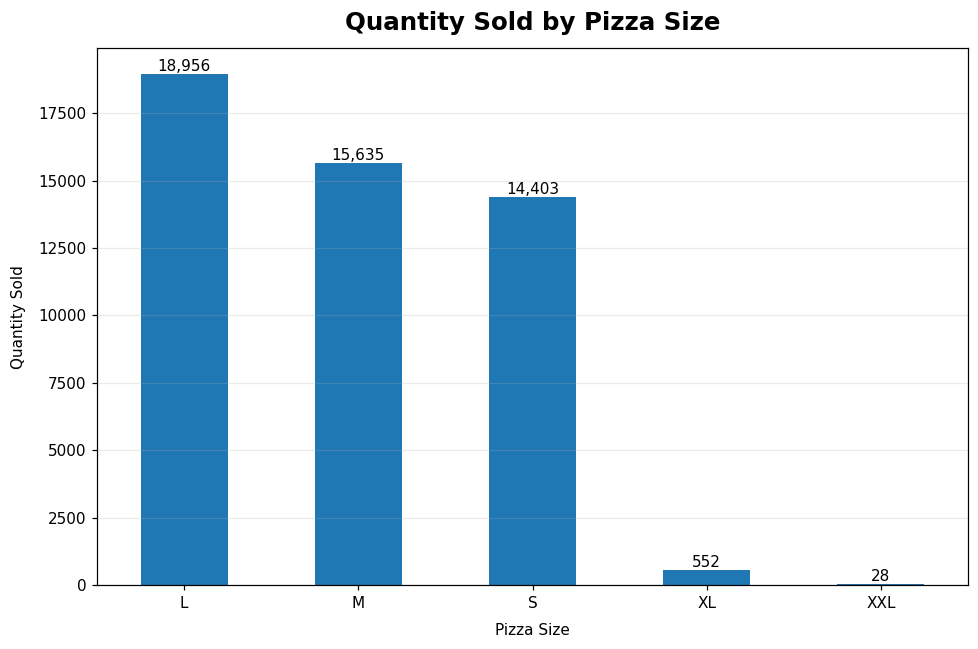

Most purchased size: L


In [14]:
size_quantity = df.groupby('pizza_size')['quantity'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 6))
ax = size_quantity.plot(kind='bar')

plt.title('Quantity Sold by Pizza Size', fontsize=16, fontweight='bold')
plt.xlabel('Pizza Size')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(size_quantity):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print('Most purchased size:', size_quantity.idxmax())


# Top 10 Pizzas by Revenue

### What are we trying to understand?
Which individual pizzas contribute the most revenue?

### How to read the chart
The horizontal layout makes long pizza names easier to read. The pizzas are sorted so the highest-revenue products stand out immediately.


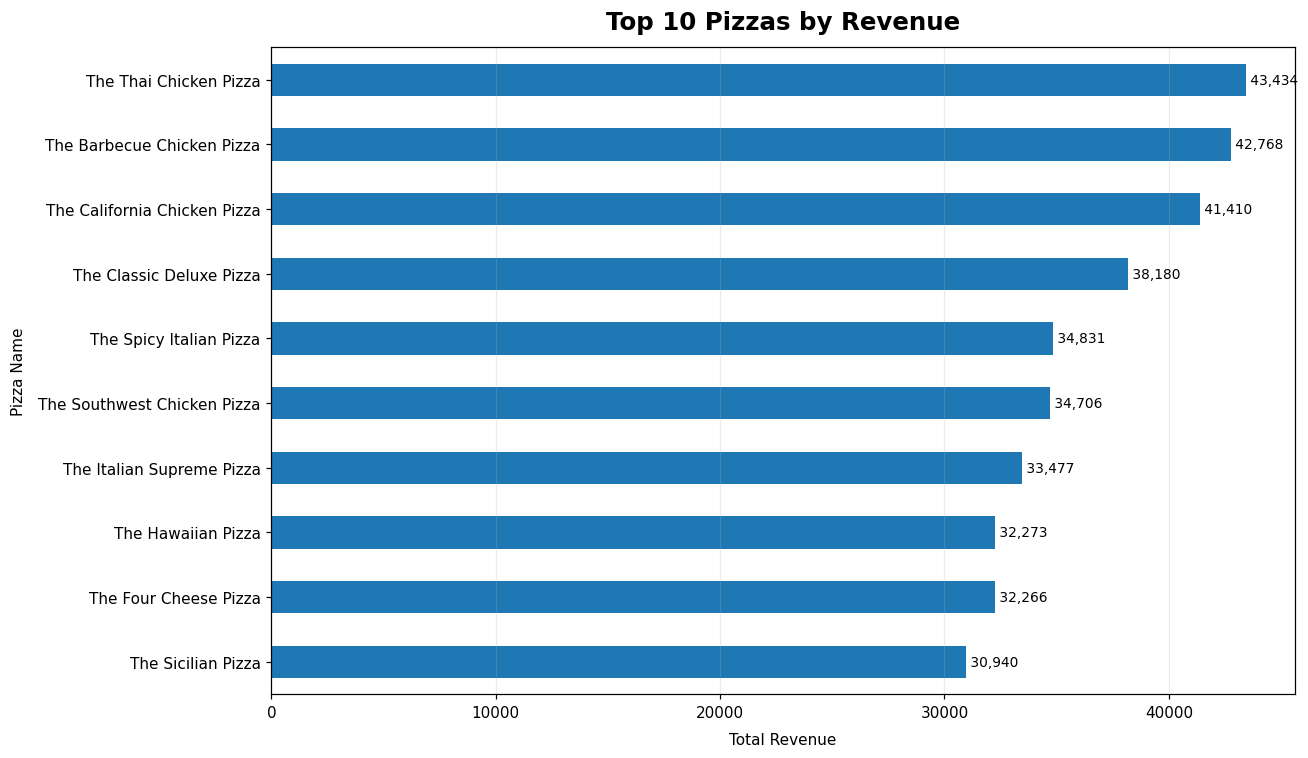

Top revenue pizza: The Thai Chicken Pizza
Top pizza revenue: 43,434.25


In [15]:
top_pizzas_revenue = df.groupby('pizza_name')['total_price'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 7))
ax = top_pizzas_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Pizzas by Revenue', fontsize=16, fontweight='bold')
plt.xlabel('Total Revenue')
plt.ylabel('Pizza Name')
plt.grid(axis='x', alpha=0.25)

for i, v in enumerate(top_pizzas_revenue.sort_values()):
    ax.text(v, i, f' {v:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('Top revenue pizza:', top_pizzas_revenue.index[0])
print(f'Top pizza revenue: {top_pizzas_revenue.iloc[0]:,.2f}')


# Top 10 Pizzas by Quantity

This chart identifies the pizzas that customers order most frequently.

### Revenue vs Quantity
Use this together with the previous chart:
- **Revenue ranking** tells us which pizzas earn the most.
- **Quantity ranking** tells us which pizzas are ordered most often.


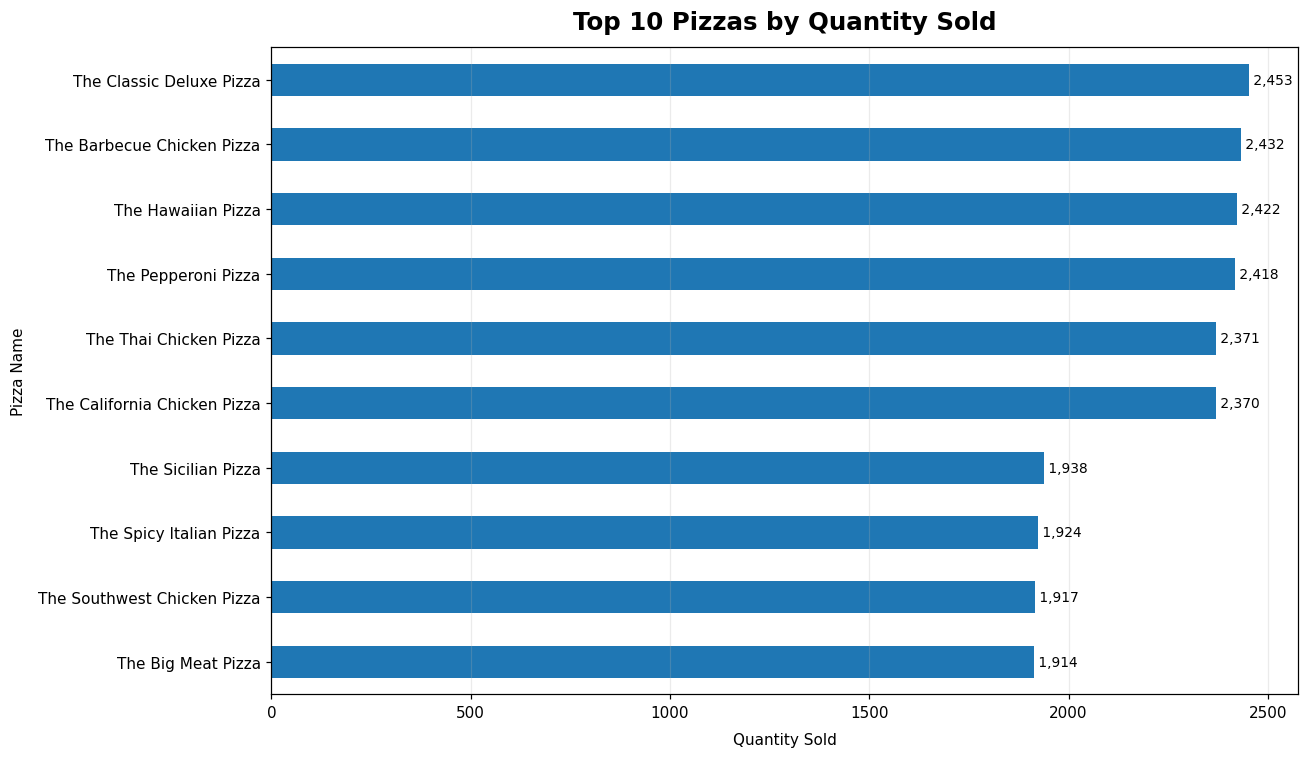

Most ordered pizza: The Classic Deluxe Pizza
Quantity sold: 2,453


In [16]:
top_pizzas_quantity = df.groupby('pizza_name')['quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 7))
ax = top_pizzas_quantity.sort_values().plot(kind='barh')

plt.title('Top 10 Pizzas by Quantity Sold', fontsize=16, fontweight='bold')
plt.xlabel('Quantity Sold')
plt.ylabel('Pizza Name')
plt.grid(axis='x', alpha=0.25)

for i, v in enumerate(top_pizzas_quantity.sort_values()):
    ax.text(v, i, f' {v:,.0f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print('Most ordered pizza:', top_pizzas_quantity.index[0])
print(f'Quantity sold: {top_pizzas_quantity.iloc[0]:,.0f}')


# Monthly Revenue Trend

### What are we trying to understand?
Does revenue change over time?

A line chart is used because **time is continuous**. Peaks show stronger revenue periods, while dips show weaker periods.

The points are labelled with revenue values so the trend is easier to explain.


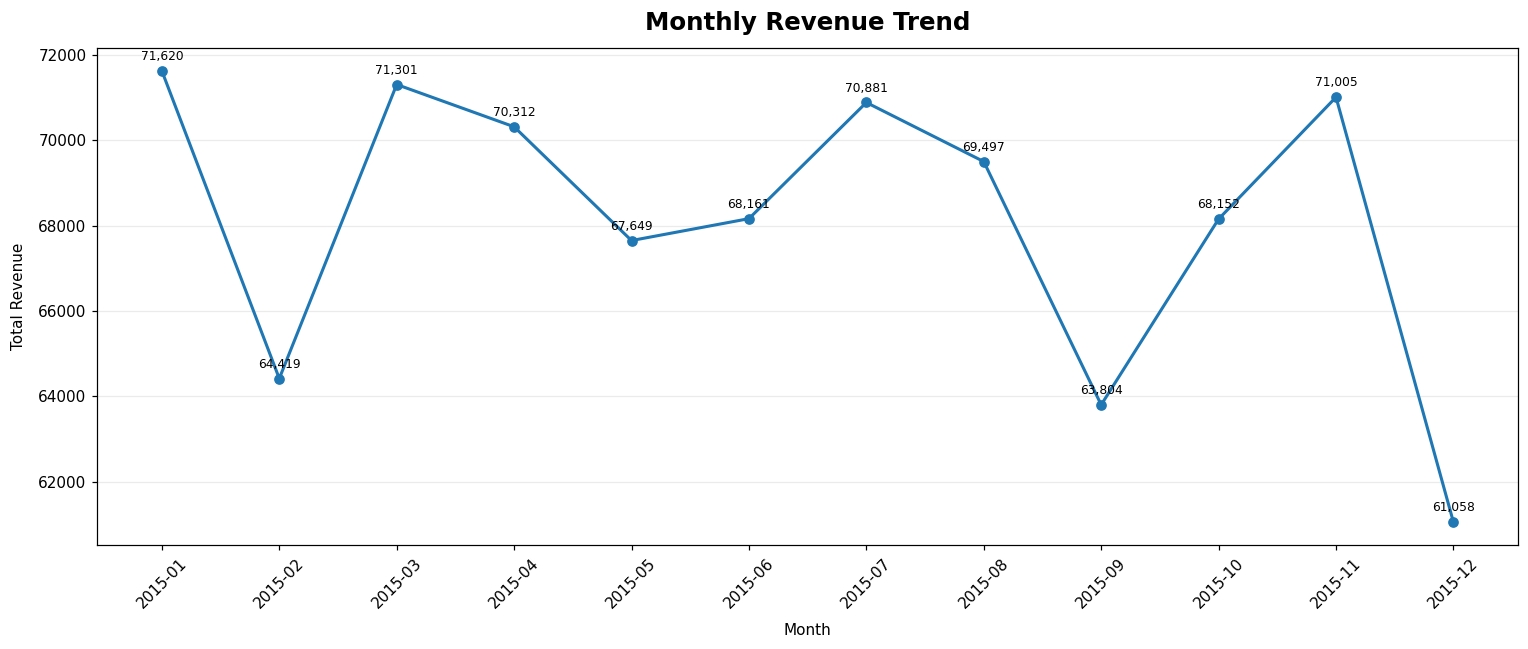

Highest revenue month: 2015-01
Revenue: 71,620.15


In [17]:
# Monthly revenue analysis
# Year and Month are created in the DATE & TIME CONVERSION cell above.

monthly_revenue = (
    df.dropna(subset=['Year', 'Month', 'total_price'])
      .groupby(['Year', 'Month'])['total_price']
      .sum()
      .sort_index()
)

monthly_labels = [
    f'{int(year)}-{int(month):02d}'
    for year, month in monthly_revenue.index
]

plt.figure(figsize=(14, 6))
plt.plot(
    range(len(monthly_revenue)),
    monthly_revenue.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Revenue Trend', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(
    range(len(monthly_revenue)),
    monthly_labels,
    rotation=45
)
plt.grid(axis='y', alpha=0.25)

for i, value in enumerate(monthly_revenue.values):
    plt.annotate(
        f'{value:,.0f}',
        (i, value),
        textcoords='offset points',
        xytext=(0, 7),
        ha='center',
        fontsize=8
    )

plt.tight_layout()
plt.show()

if not monthly_revenue.empty:
    best_month = monthly_revenue.idxmax()
    print(f'Highest revenue month: {int(best_month[0])}-{int(best_month[1]):02d}')
    print(f'Revenue: {monthly_revenue.max():,.2f}')


# Daily Revenue Trend

Daily data contains many observations, so this graph is mainly used to understand the overall movement and identify unusually high or low periods.

For presentation purposes, focus on the **overall trend and major peaks**, rather than trying to read every single day.


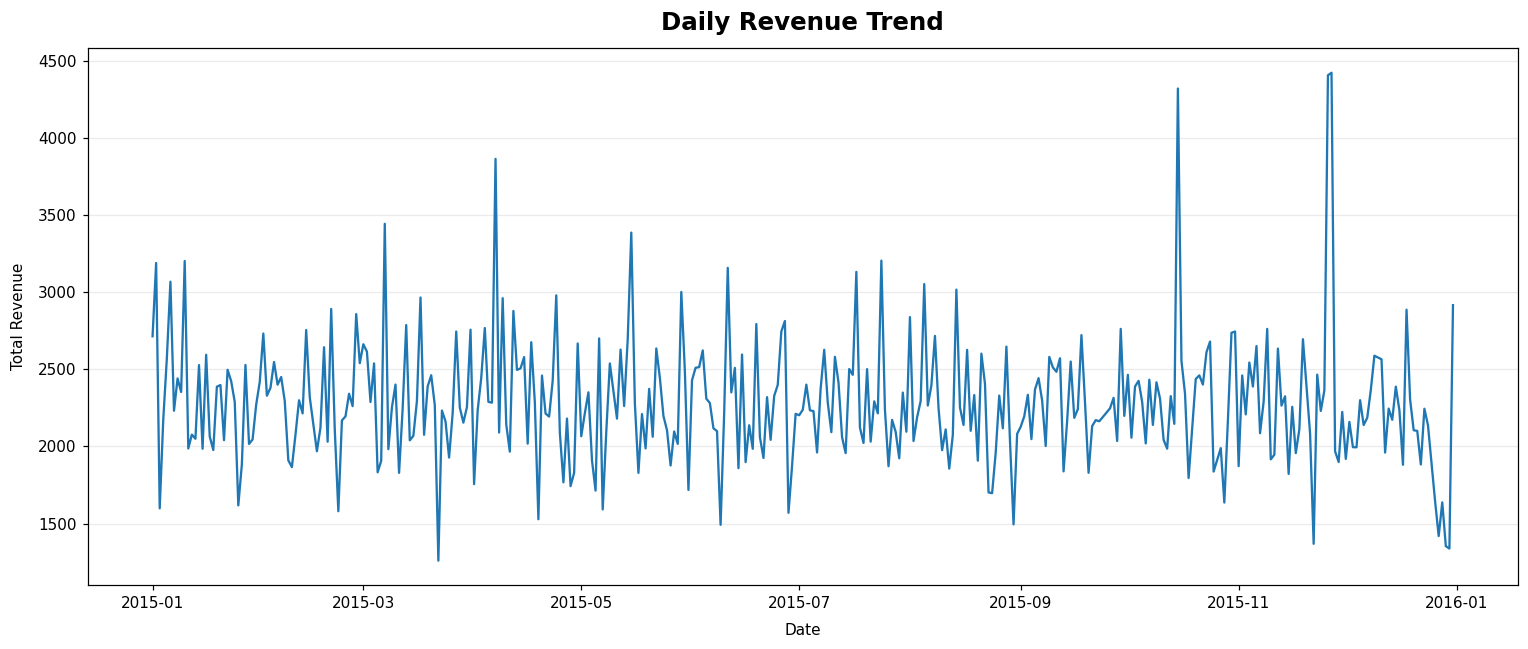

Highest daily revenue: 4,422.45
Date of highest daily revenue: 2015-11-27


In [18]:
daily_revenue = (
    df.dropna(subset=['order_date', 'total_price'])
      .groupby('order_date')['total_price']
      .sum()
      .sort_index()
)

plt.figure(figsize=(14, 6))
plt.plot(daily_revenue.index, daily_revenue.values)

plt.title('Daily Revenue Trend', fontsize=16, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Revenue')
plt.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

if not daily_revenue.empty:
    print(f'Highest daily revenue: {daily_revenue.max():,.2f}')
    print(f'Date of highest daily revenue: {daily_revenue.idxmax().date()}')


# Revenue by Day of Week

### What are we trying to understand?
Which day of the week generates the most revenue?

This is useful for:
- staffing decisions,
- promotional campaigns,
- inventory planning,
- identifying busy and slow days.


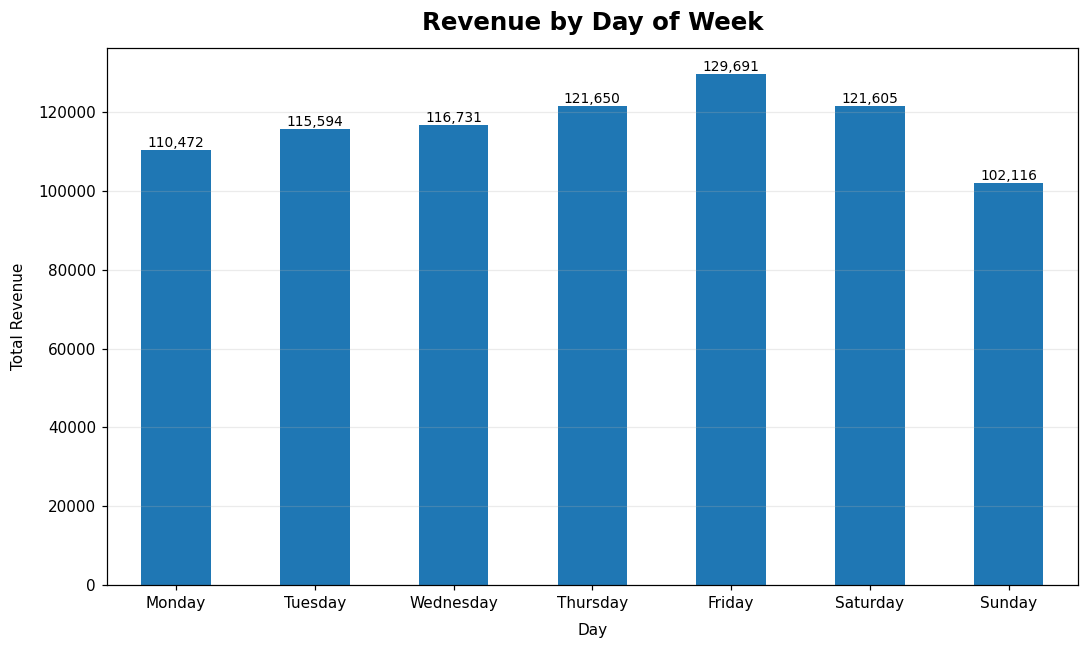

Highest revenue day: Friday


In [19]:
day_revenue = df.groupby('Day_Name')['total_price'].sum()

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_revenue = day_revenue.reindex(day_order)

plt.figure(figsize=(10, 6))
ax = day_revenue.plot(kind='bar')

plt.title('Revenue by Day of Week', fontsize=16, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(day_revenue):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print('Highest revenue day:', day_revenue.idxmax())


# Revenue by Order Period

### What are we trying to understand?
At what part of the day are orders generating the most revenue?

The periods were created from the order hour:
- Late Night
- Morning
- Lunch
- Afternoon
- Evening
- Night

This makes the time-of-day pattern easier to understand than looking at hundreds of individual timestamps.


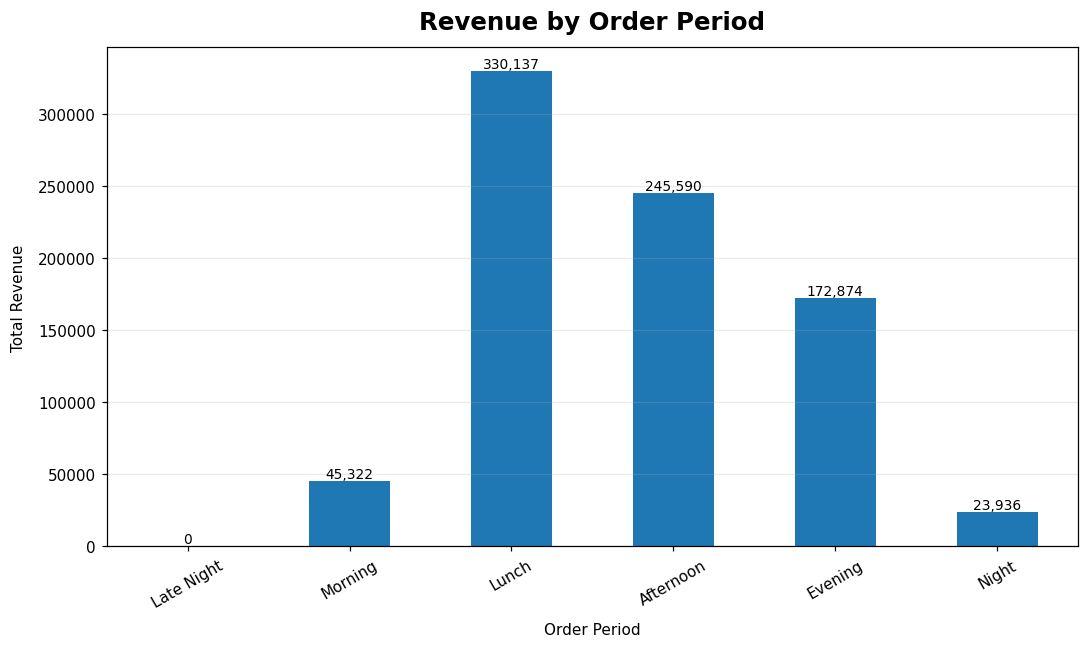

Highest revenue period: Lunch


In [20]:
period_revenue = df.groupby('order_period', observed=False)['total_price'].sum()

plt.figure(figsize=(10, 6))
ax = period_revenue.plot(kind='bar')

plt.title('Revenue by Order Period', fontsize=16, fontweight='bold')
plt.xlabel('Order Period')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.25)

for i, v in enumerate(period_revenue):
    ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print('Highest revenue period:', period_revenue.idxmax())


### 7. QUANTITY SOLD BY PIZZA SIZE


pizza_size
L      18956.0
M      15635.0
S      14403.0
XL       552.0
XXL       28.0
Name: quantity, dtype: float64


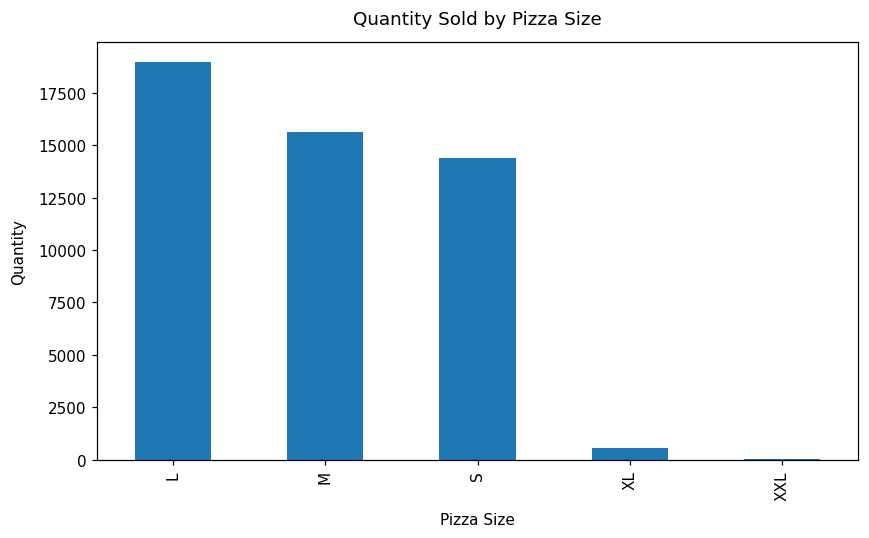

In [21]:
size_quantity = df.groupby('pizza_size')['quantity'].sum().sort_values(ascending=False)
print(size_quantity)

plt.figure(figsize=(8,5))
size_quantity.plot(kind='bar')
plt.title('Quantity Sold by Pizza Size')
plt.xlabel('Pizza Size')
plt.ylabel('Quantity')
plt.tight_layout()
plt.show()


### 8. TOP 10 PIZZAS BY REVENUE


pizza_name
The Thai Chicken Pizza          43434.25
The Barbecue Chicken Pizza      42768.00
The California Chicken Pizza    41409.50
The Classic Deluxe Pizza        38180.50
The Spicy Italian Pizza         34831.25
The Southwest Chicken Pizza     34705.75
The Italian Supreme Pizza       33476.75
The Hawaiian Pizza              32273.25
The Four Cheese Pizza           32265.70
The Sicilian Pizza              30940.50
Name: total_price, dtype: float64


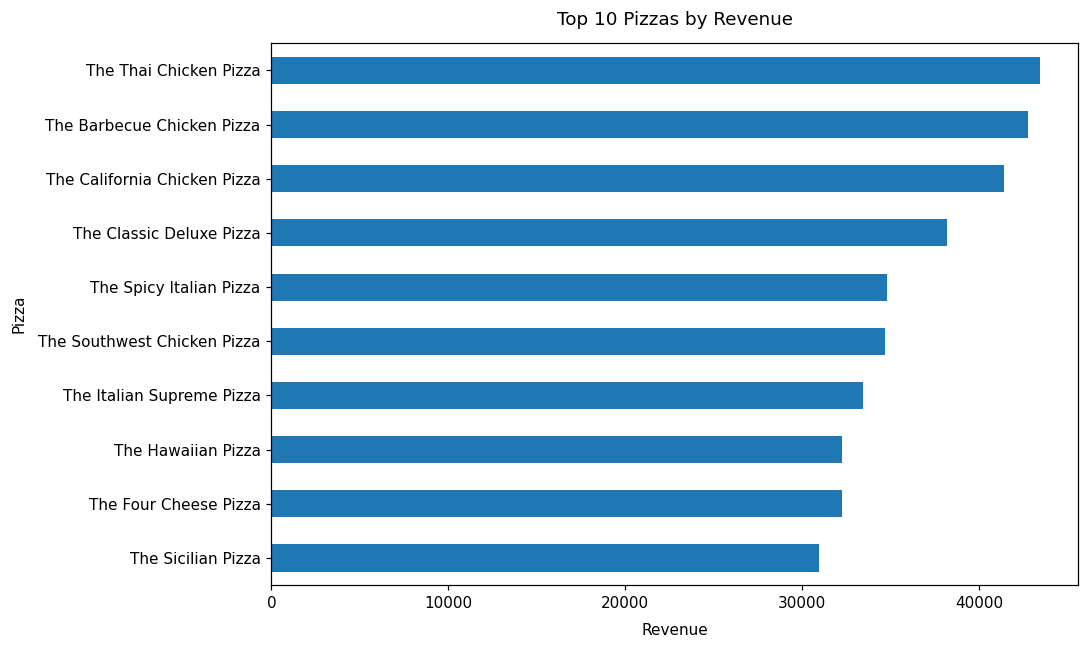

In [22]:
top_pizzas_revenue = df.groupby('pizza_name')['total_price'].sum().sort_values(ascending=False).head(10)
print(top_pizzas_revenue)

plt.figure(figsize=(10,6))
top_pizzas_revenue.sort_values().plot(kind='barh')
plt.title('Top 10 Pizzas by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Pizza')
plt.tight_layout()
plt.show()


### 9. TOP 10 PIZZAS BY QUANTITY


pizza_name
The Classic Deluxe Pizza        2453.0
The Barbecue Chicken Pizza      2432.0
The Hawaiian Pizza              2422.0
The Pepperoni Pizza             2418.0
The Thai Chicken Pizza          2371.0
The California Chicken Pizza    2370.0
The Sicilian Pizza              1938.0
The Spicy Italian Pizza         1924.0
The Southwest Chicken Pizza     1917.0
The Big Meat Pizza              1914.0
Name: quantity, dtype: float64


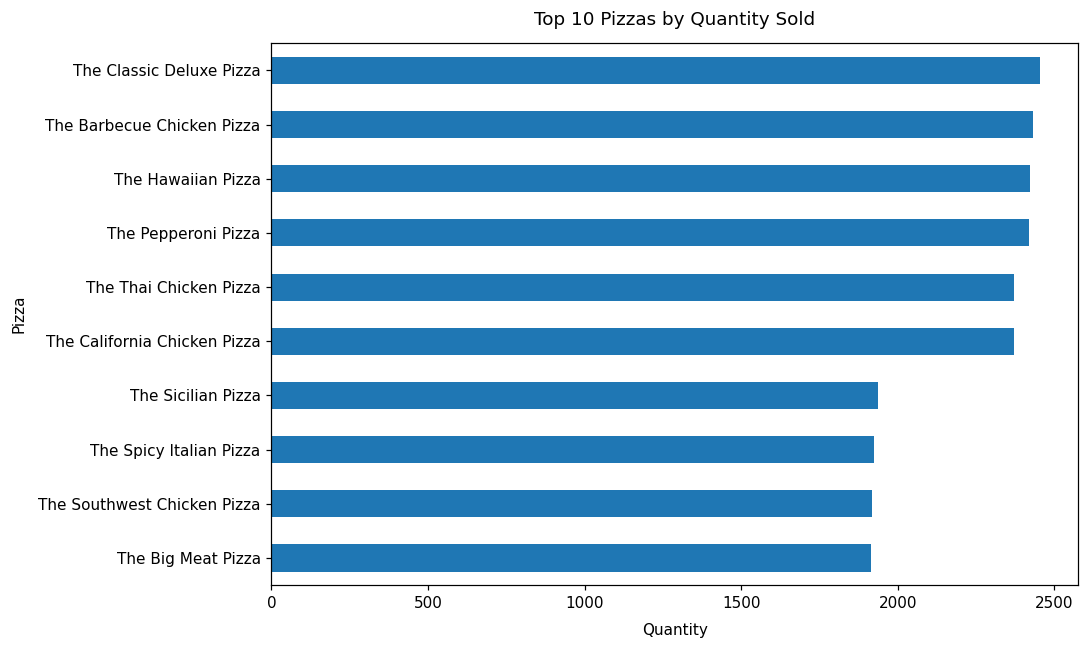

In [23]:
top_pizzas_quantity = df.groupby('pizza_name')['quantity'].sum().sort_values(ascending=False).head(10)
print(top_pizzas_quantity)

plt.figure(figsize=(10,6))
top_pizzas_quantity.sort_values().plot(kind='barh')
plt.title('Top 10 Pizzas by Quantity Sold')
plt.xlabel('Quantity')
plt.ylabel('Pizza')
plt.tight_layout()
plt.show()


### 10. MONTHLY REVENUE


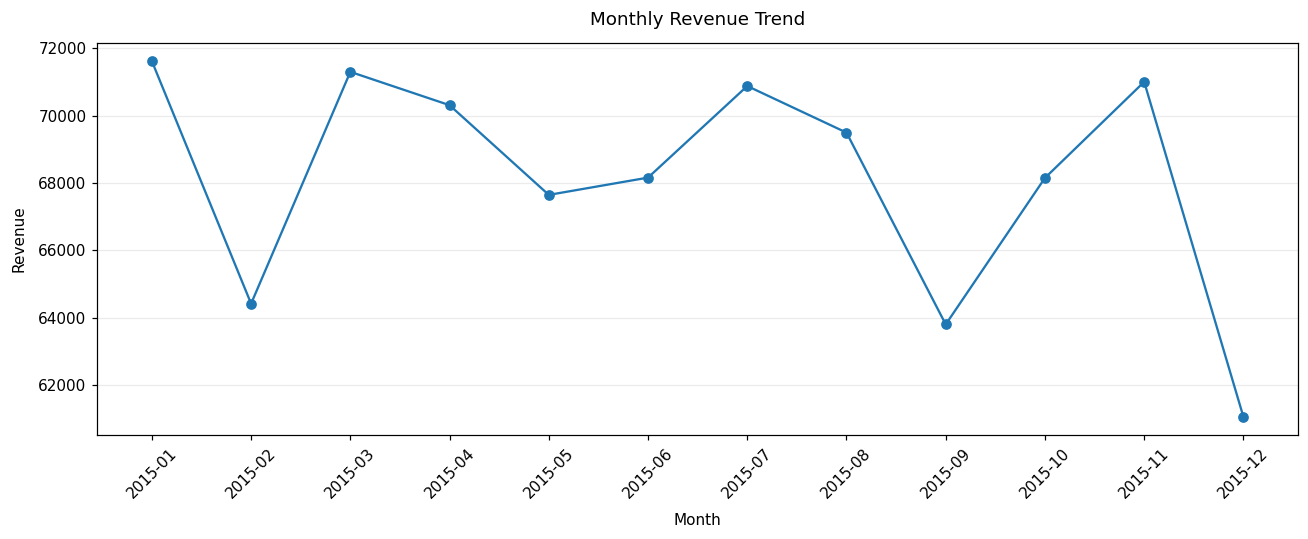

In [24]:
monthly_revenue = (
    df.dropna(subset=['Year', 'Month', 'total_price'])
      .groupby(['Year', 'Month'])['total_price']
      .sum()
      .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(range(len(monthly_revenue)), monthly_revenue.values, marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(
    range(len(monthly_revenue)),
    [f'{int(y)}-{int(m):02d}' for y, m in monthly_revenue.index],
    rotation=45
)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


### 11. DAILY REVENUE


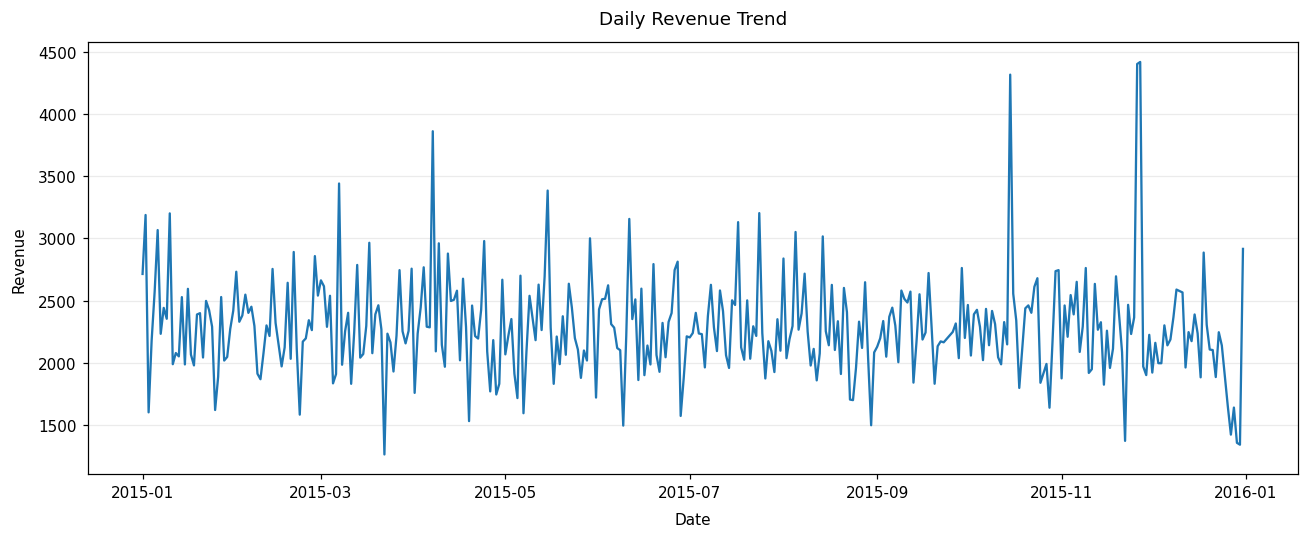

In [25]:
daily_revenue = (
    df.dropna(subset=['order_date', 'total_price'])
      .groupby('order_date')['total_price']
      .sum()
      .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(daily_revenue.index, daily_revenue.values)
plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


### 12. REVENUE BY DAY NAME


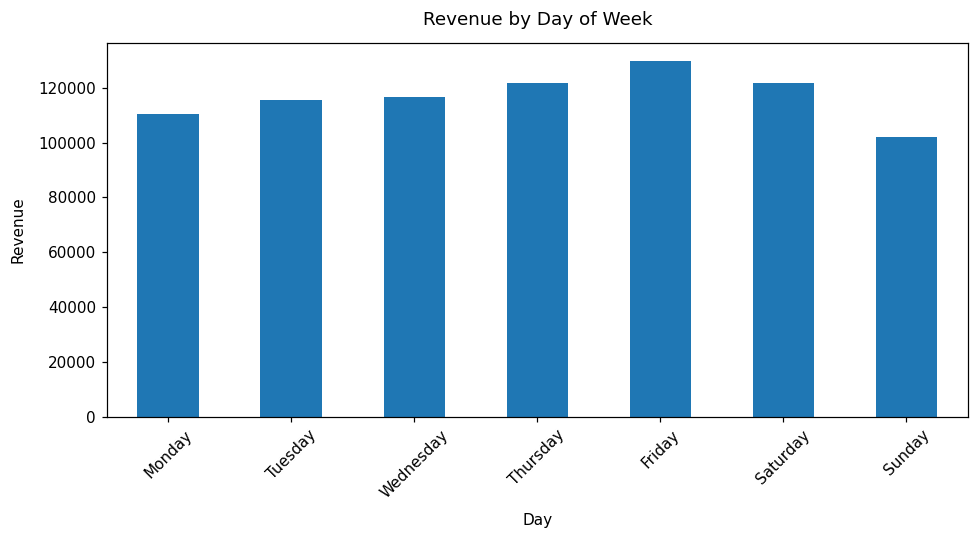

In [26]:
day_revenue = df.groupby('Day_Name')['total_price'].sum()
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_revenue = day_revenue.reindex(day_order)

plt.figure(figsize=(9,5))
day_revenue.plot(kind='bar')
plt.title('Revenue by Day of Week')
plt.xlabel('Day')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 13. REVENUE BY ORDER PERIOD


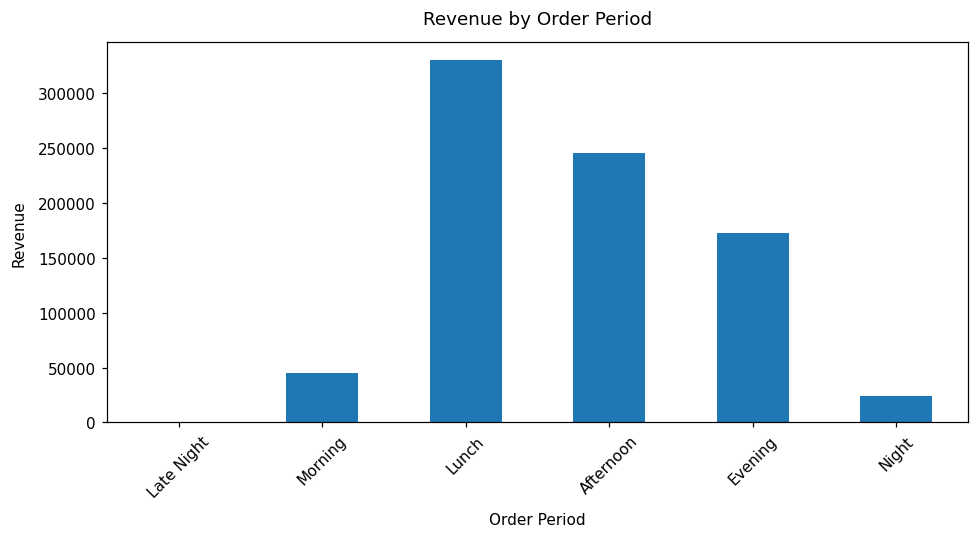

In [27]:
period_revenue = df.groupby('order_period', observed=False)['total_price'].sum()

plt.figure(figsize=(9,5))
period_revenue.plot(kind='bar')
plt.title('Revenue by Order Period')
plt.xlabel('Order Period')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 14. CORRELATION ANALYSIS


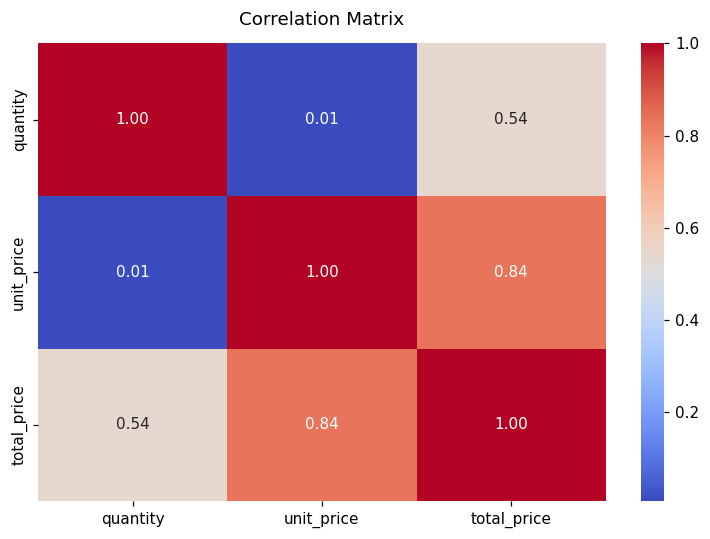

In [28]:
numeric_cols = ['quantity', 'unit_price', 'total_price']
corr = df[numeric_cols].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


## ⚙️ FEATURE ENGINEERING

Feature engineering means creating useful variables from the original dataset.

### Features used by the model

| Feature | Meaning |
|---|---|
| `quantity` | Number of pizzas in the record |
| `unit_price` | Price of one pizza |
| `pizza_size` | Size of the pizza |
| `pizza_category` | Pizza category |
| `Year` | Year of the order |
| `Month` | Month number |
| `Day` | Day of the month |
| `Day_of_Week` | Numeric day of week |
| `order_hour` | Hour when the order was placed |
| `order_period` | Business-friendly time group |

### Target variable

**`total_price`** is the value the model is asked to predict.

Categorical variables such as pizza size and category are converted into numeric dummy variables using one-hot encoding.


The machine-learning dataset is prepared separately so the original sales data remains unchanged.

The target variable is **`total_price`**. We use quantity, unit price, product characteristics, and time features as predictors.

Because date/time conversion can create missing values when an invalid value is encountered, the model dataset is cleaned before training. Categorical columns are converted to numeric dummy variables.


In [29]:
# Create a fresh dataset for machine learning
model_df = df.copy()

# Remove rows where the target or required model features are missing
required_columns = [
    'total_price',
    'quantity',
    'unit_price',
    'pizza_size',
    'pizza_category',
    'Year',
    'Month',
    'Day',
    'Day_of_Week',
    'order_hour'
]

model_df = model_df.dropna(subset=required_columns).copy()

features = [
    'quantity',
    'unit_price',
    'pizza_size',
    'pizza_category',
    'Year',
    'Month',
    'Day',
    'Day_of_Week',
    'order_hour'
]

X = model_df[features].copy()
y = pd.to_numeric(model_df['total_price'], errors='coerce')

# Remove any rows where target became invalid
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Convert categorical variables to numeric columns
X = pd.get_dummies(
    X,
    columns=['pizza_size', 'pizza_category'],
    drop_first=True,
    dtype=float
)

# Final safety check
X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

print("Original rows:", len(df))
print("Rows used for ML:", len(X))
print("Features after encoding:", X.shape[1])
print("Missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

X.head()


Original rows: 48620
Rows used for ML: 48620
Features after encoding: 14
Missing values in X: 0
Missing values in y: 0


,quantity,unit_price,Year,Month,Day,Day_of_Week,order_hour,pizza_size_M,pizza_size_S,pizza_size_XL,pizza_size_XXL,pizza_category_Classic,pizza_category_Supreme,pizza_category_Veggie
0,1.0,13.25,2015,1,1,3,11,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,1.0,16.00,2015,1,1,3,11,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1.0,18.50,2015,1,1,3,11,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,20.75,2015,1,1,3,11,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1.0,16.00,2015,1,1,3,11,1.0,0.0,0.0,0.0,0.0,0.0,1.0


## ✂️ TRAIN-TEST SPLIT

The cleaned dataset is divided into two parts:

- **80% Training Data** – used by the model to learn relationships.
- **20% Testing Data** – used to evaluate how well the trained model performs on unseen records.

`random_state=42` is used so the same split can be reproduced each time the notebook is run.


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records :", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test :", X_test.isna().sum().sum())


Training records: 38896
Testing records : 9724
Training features: 14
Missing values in X_train: 0
Missing values in X_test : 0


## 🤖 LINEAR REGRESSION MODEL

Linear Regression is a supervised machine-learning algorithm used for predicting a **continuous numerical value**.

In this project, the continuous target is:

> **`total_price`**

The model learns how the selected features are associated with the total order value.

### Why Linear Regression?

It is simple, fast, easy to explain, and suitable as a baseline regression model for a college-level analytics project.

### Important interpretation

Because `total_price` is mathematically related to the quantity and unit price of the order, the model can achieve a very high R² score. This is expected and should be mentioned when presenting the project.


In [31]:
model = LinearRegression()

model.fit(
    X_train,
    y_train
)

print("Linear Regression model trained successfully.")


Linear Regression model trained successfully.


### PREDICTION


In [32]:
y_pred = model.predict(X_test)

prediction_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

prediction_df['Error'] = prediction_df['Actual'] - prediction_df['Predicted']
prediction_df['Absolute_Error'] = prediction_df['Error'].abs()

prediction_df.head(10)


,Actual,Predicted,Error,Absolute_Error
0,12.50,12.405352,0.094648,0.094648
1,13.25,13.167589,0.082411,0.082411
2,16.25,16.247941,0.002059,0.002059
3,16.50,16.486770,0.013230,0.013230
4,16.00,15.992051,0.007949,0.007949
5,20.75,20.854584,-0.104584,0.104584
6,20.75,20.851402,-0.101402,0.101402
7,16.75,16.772445,-0.022445,0.022445
8,20.50,20.546533,-0.046533,0.046533
9,20.75,20.834065,-0.084065,0.084065


## 📊 MODEL EVALUATION

Four metrics are used to evaluate the regression model.

### MAE — Mean Absolute Error
Average absolute difference between actual and predicted revenue.

**Lower MAE = better.**

### MSE — Mean Squared Error
Squares each prediction error before averaging, so larger errors receive more weight.

**Lower MSE = better.**

### RMSE — Root Mean Squared Error
Square root of MSE. It is expressed in the same unit as `total_price`, making it easier to interpret.

**Lower RMSE = better.**

### R² — R-Squared
Shows how much of the variation in the target is explained by the model.

- Closer to **1** → stronger explanatory performance.
- Closer to **0** → weaker explanatory performance.

No single metric should be interpreted alone.


### MEAN ABSOLUTE ERROR (MAE)


In [33]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)


Mean Absolute Error (MAE): 0.1239769624733055


### MEAN SQUARED ERROR (MSE)


In [34]:
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)


Mean Squared Error (MSE): 0.3107460284159966


### ROOT MEAN SQUARED ERROR (RMSE)


In [35]:
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)


Root Mean Squared Error (RMSE): 0.5574459869942527


### R-SQUARED SCORE


In [36]:
r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)


R² Score: 0.98447244240479


### MODEL PERFORMANCE SUMMARY


In [37]:
metrics = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Value': [mae, mse, rmse, r2]
})

metrics


,Metric,Value
0,MAE,0.123977
1,MSE,0.310746
2,RMSE,0.557446
3,R² Score,0.984472


## <font color="Blue"> ACTUAL VS PREDICTED REVENUE </FONT>


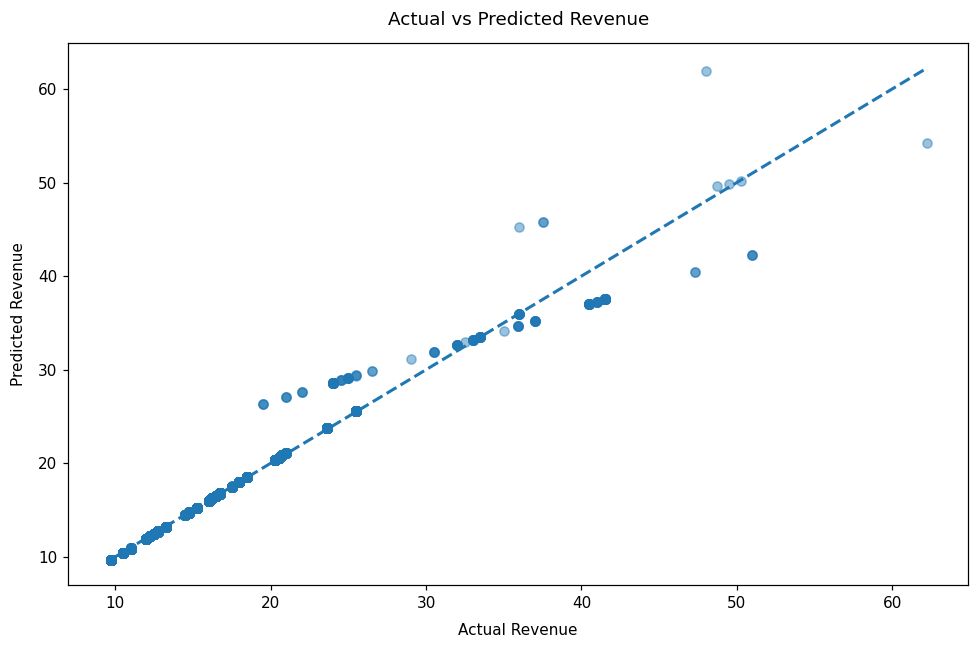

In [38]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.45
)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    linewidth=2
)

plt.xlabel('Actual Revenue')
plt.ylabel('Predicted Revenue')
plt.title('Actual vs Predicted Revenue')
plt.tight_layout()
plt.show()


## <font color="Blue"> RESIDUAL ANALYSIS </FONT>


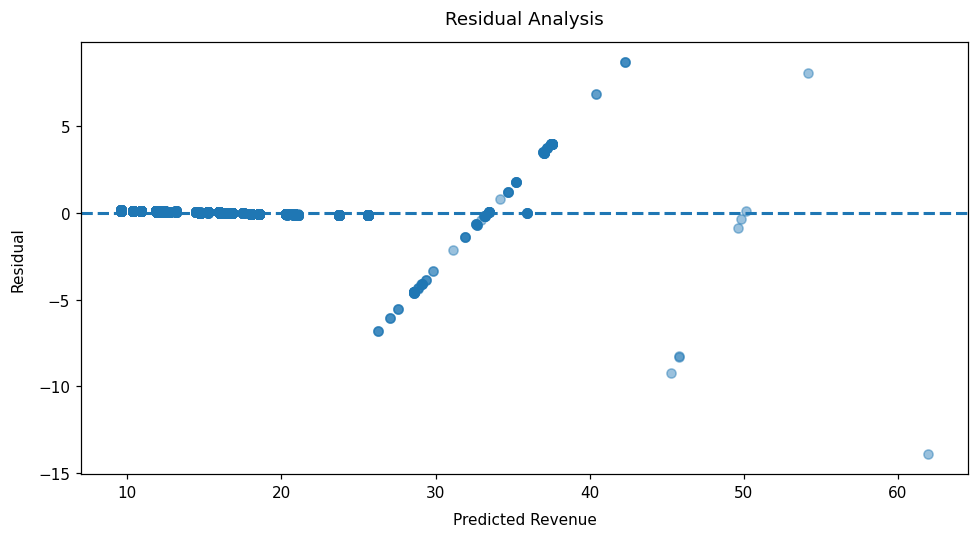

In [39]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 5))
plt.scatter(
    y_pred,
    residuals,
    alpha=0.45
)
plt.axhline(0, linestyle='--', linewidth=2)

plt.xlabel('Predicted Revenue')
plt.ylabel('Residual')
plt.title('Residual Analysis')
plt.tight_layout()
plt.show()


### RESIDUAL DISTRIBUTION


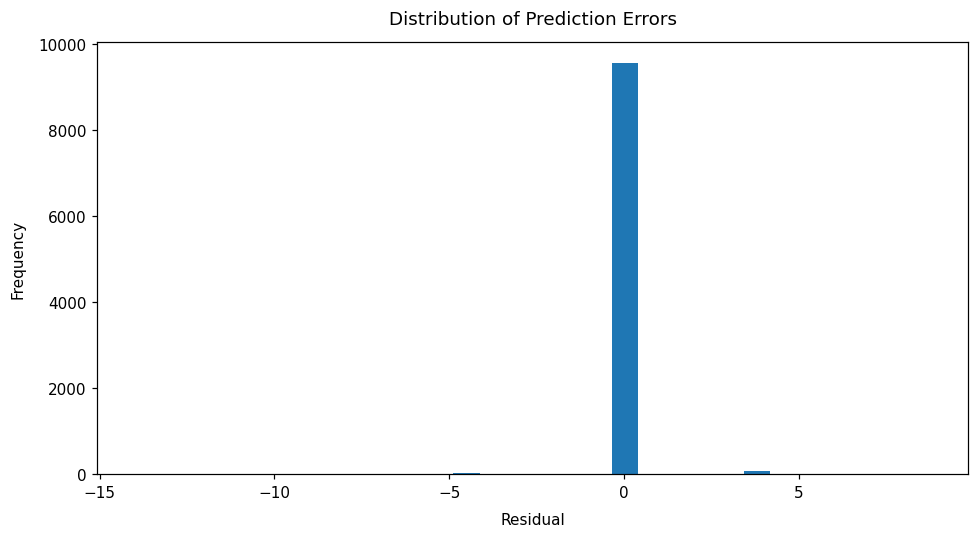

In [40]:
plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=30)
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.title('Distribution of Prediction Errors')
plt.tight_layout()
plt.show()


## <font color="Blue"> MODEL COEFFICIENTS </FONT>


In [41]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients['Absolute_Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    'Absolute_Coefficient',
    ascending=False
)

coefficients.head(15)


,Feature,Coefficient,Absolute_Coefficient
0,quantity,1.668414e+01,1.668414e+01
1,unit_price,1.015410e+00,1.015410e+00
10,pizza_size_XXL,-2.864916e-01,2.864916e-01
11,pizza_category_Classic,-5.176379e-02,5.176379e-02
9,pizza_size_XL,-2.690811e-02,2.690811e-02
8,pizza_size_S,-2.484866e-02,2.484866e-02
12,pizza_category_Supreme,-2.232935e-02,2.232935e-02
7,pizza_size_M,-2.054551e-02,2.054551e-02
13,pizza_category_Veggie,-1.363724e-02,1.363724e-02
5,Day_of_Week,9.114559e-04,9.114559e-04


### TOP MODEL FEATURES


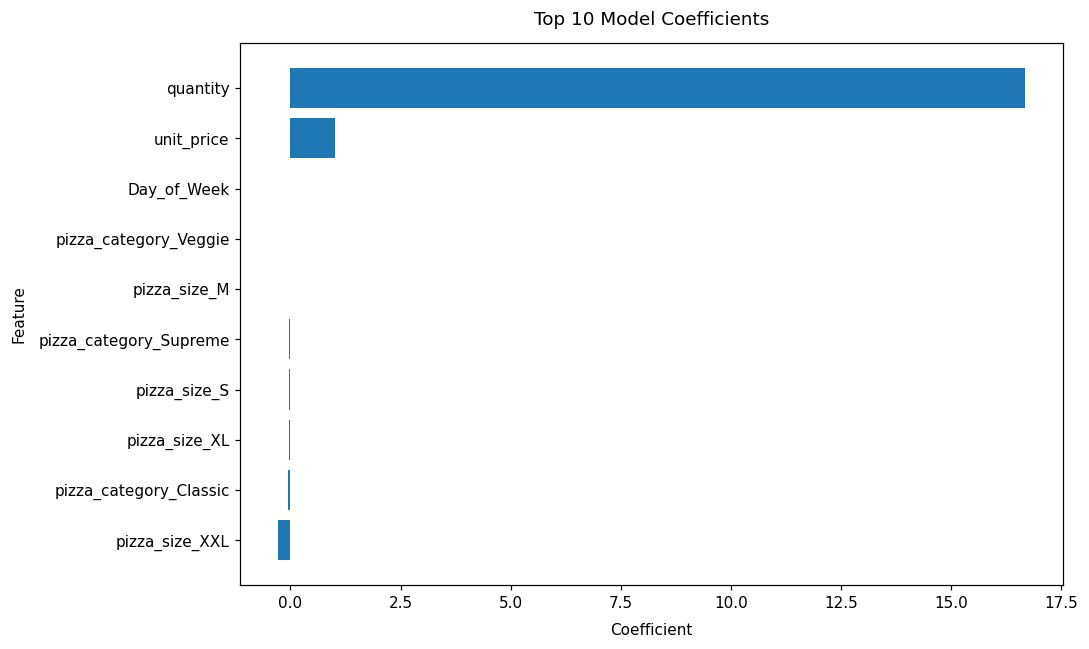

In [42]:
top_coefficients = coefficients.head(10).sort_values('Coefficient')

plt.figure(figsize=(10, 6))
plt.barh(top_coefficients['Feature'], top_coefficients['Coefficient'])
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Top 10 Model Coefficients')
plt.tight_layout()
plt.show()


## <font color="Blue"> BUSINESS INSIGHTS </FONT>


In [43]:
print("===== BUSINESS INSIGHTS =====")

print("\nTotal Revenue:")
print(f"{df['total_price'].sum():,.2f}")

print("\nTotal Quantity Sold:")
print(f"{df['quantity'].sum():,}")

print("\nTop 5 Pizzas by Revenue:")
print(top_pizzas_revenue.head(5))

print("\nTop 5 Pizzas by Quantity:")
print(top_pizzas_quantity.head(5))

print("\nHighest Revenue Category:")
print(category_revenue.idxmax())

print("\nHighest Revenue Size:")
print(size_revenue.idxmax())

print("\nHighest Revenue Day:")
print(day_revenue.idxmax())

print("\nHighest Revenue Order Period:")
print(period_revenue.idxmax())

print("\nModel R² Score:")
print(round(r2, 4))


===== BUSINESS INSIGHTS =====

Total Revenue:
817,860.05

Total Quantity Sold:
49,574.0

Top 5 Pizzas by Revenue:
pizza_name
The Thai Chicken Pizza          43434.25
The Barbecue Chicken Pizza      42768.00
The California Chicken Pizza    41409.50
The Classic Deluxe Pizza        38180.50
The Spicy Italian Pizza         34831.25
Name: total_price, dtype: float64

Top 5 Pizzas by Quantity:
pizza_name
The Classic Deluxe Pizza      2453.0
The Barbecue Chicken Pizza    2432.0
The Hawaiian Pizza            2422.0
The Pepperoni Pizza           2418.0
The Thai Chicken Pizza        2371.0
Name: quantity, dtype: float64

Highest Revenue Category:
Classic

Highest Revenue Size:
L

Highest Revenue Day:
Friday

Highest Revenue Order Period:
Lunch

Model R² Score:
0.9845


## <font color="Blue"> CONCLUSION </FONT>


This project analyzed pizza sales data using Python, Pandas, data visualization, and machine learning techniques.

The analysis examined total revenue, quantity sold, pizza categories, pizza sizes, individual pizza performance, monthly revenue trends, daily revenue trends, and order periods.

A Linear Regression model was developed to predict `total_price` using quantity, unit price, pizza size, pizza category, and date/time-related features. The model was evaluated using MAE, MSE, RMSE, and R² Score.

The project demonstrates how historical pizza sales data can be transformed into meaningful business insights and used for predictive analytics.

**Important modeling note:** `total_price` is closely related to `quantity × unit_price` in a pizza sales transaction dataset. Therefore, a very high R² score is expected when both quantity and unit price are included as predictors. This makes the model useful as a demonstration of regression, but it should not be interpreted as a difficult long-term forecasting model.

For future improvement, the project can predict **daily or monthly revenue** instead of individual transaction revenue, which would provide a more realistic business forecasting problem.


## <font color="Blue"> FUTURE ENHANCEMENTS </FONT>

- Compare Linear Regression with Random Forest Regressor and Gradient Boosting.
- Build a daily/monthly revenue forecasting model.
- Add a dashboard using Power BI, Tableau, or Streamlit.
- Analyze peak ordering hours and days for staffing and promotions.
- Use pizza-level demand forecasting for inventory planning.


# 📋 EXECUTIVE SUMMARY

This section brings the most important findings together in one place.

A good business presentation should answer five questions:

1. **How much revenue was generated?**
2. **Which category and size performed best?**
3. **Which pizzas were the strongest products?**
4. **When did customers generate the most revenue?**
5. **How well did the prediction model perform?**


In [44]:
print("=" * 55)
print("           PIZZA SALES PROJECT SUMMARY")
print("=" * 55)

print(f"Total Revenue              : {df['total_price'].sum():,.2f}")
print(f"Total Quantity Sold        : {df['quantity'].sum():,.0f}")
print(f"Average Order Value        : {df.groupby('order_id')['total_price'].sum().mean():,.2f}")
print(f"Top Revenue Category       : {category_revenue.idxmax()}")
print(f"Top Revenue Pizza Size     : {size_revenue.idxmax()}")
print(f"Top Revenue Pizza          : {top_pizzas_revenue.index[0]}")
print(f"Top Quantity Pizza         : {top_pizzas_quantity.index[0]}")
print(f"Top Revenue Day            : {day_revenue.idxmax()}")
print(f"Top Revenue Order Period   : {period_revenue.idxmax()}")

print("\nMODEL PERFORMANCE")
print(f"MAE                        : {mae:,.4f}")
print(f"RMSE                       : {rmse:,.4f}")
print(f"R² Score                   : {r2:.4f}")
print("=" * 55)


           PIZZA SALES PROJECT SUMMARY
Total Revenue              : 817,860.05
Total Quantity Sold        : 49,574
Average Order Value        : 38.31
Top Revenue Category       : Classic
Top Revenue Pizza Size     : L
Top Revenue Pizza          : The Thai Chicken Pizza
Top Quantity Pizza         : The Classic Deluxe Pizza
Top Revenue Day            : Friday
Top Revenue Order Period   : Lunch

MODEL PERFORMANCE
MAE                        : 0.1240
RMSE                       : 0.5574
R² Score                   : 0.9845


## <font color="Blue"> PROJECT END </FONT>


**Pizza Sales Revenue Prediction Analytics Using Python**


# 🎓 PRESENTATION / VIVA EXPLANATION

### What should I say when presenting this project?

**1. Problem Statement:**  
The project analyzes pizza sales data to understand revenue patterns and build a model that predicts total order value.

**2. Why EDA?**  
EDA helps us discover patterns before machine learning, such as the best category, most popular size, top pizzas, busy days, and high-revenue periods.

**3. Why Regression?**  
`total_price` is a continuous numerical value, so regression is appropriate.

**4. Why Linear Regression?**  
It is easy to understand, fast to train, and provides a strong baseline for a continuous prediction problem.

**5. What does R² mean?**  
R² indicates how much variation in the target is explained by the model. A value closer to 1 indicates stronger explanatory performance.

**6. What is an important limitation?**  
`total_price` is strongly connected to quantity and unit price. Therefore, using these variables makes the prediction task relatively direct. A more advanced project could instead predict future daily revenue, future order demand, or revenue without directly using the components of `total_price`.

### Final takeaway

The project combines **data cleaning + EDA + visualization + feature engineering + machine learning + business interpretation** into one complete analytics workflow.
